# VAE-based with PyTorch
### Example with MNIST datas (possible 1D, 2D or 3D)
## 1. Import des bibliothèques python

## 1. Import des bibliothèques python

In [99]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as Funct
from torch.optim.lr_scheduler import CosineAnnealingLR, ReduceLROnPlateau

# personnal
import libraries
import libraries.data_loader as dl
from libraries.display import display_group_images

import libraries.models as model
from libraries.model_parts.cnn import get_coder, CNN_28x28, TCNN_28x28

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Load MNIST and RT-MNIST

In [2]:
path = r"datas/mnist.npz"
keys = ['x_train', 'y_train', 'x_test', 'y_test']

X_TRAIN, Y_TRAIN, X_VAL, Y_VAL = dl.load_datas(path, keys)


X_TRAIN = X_TRAIN.reshape((60000, 1, 28, 28))
X_VAL = X_VAL[:].reshape((10000, 1, 28, 28))


X_TRAIN.shape, X_VAL.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

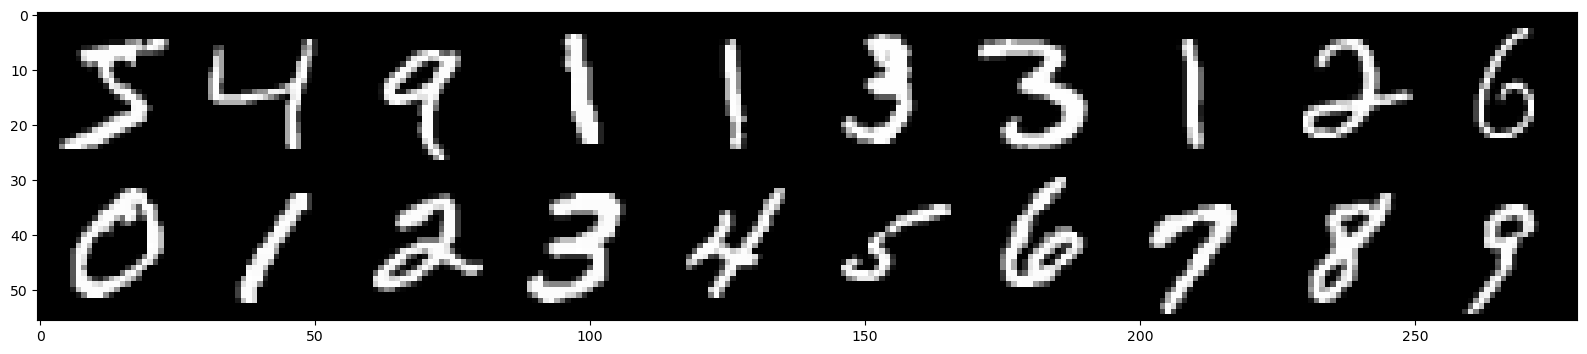

In [3]:
index = 20
display_group_images(X_TRAIN[:index], cmap = "gray")

In [4]:
X_TRAIN.max(), X_VAL.max()

(255, 255)

In [105]:
X_TRAIN.shape, X_VAL.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

## 3. Model

In [6]:
%autoreload 2
F = X_TRAIN.shape[1]
D = 50
FILTER = 16


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CNN = CNN_28x28(F, FILTER)
TCNN = TCNN_28x28(F, FILTER)
Encoder, Decoder = get_coder(CNN, TCNN, D, F, (28, 28))
network = model.VAE(Encoder = Encoder, Decoder = Decoder)

In [7]:
X_batch = X_TRAIN[:5].astype(np.float32) /255.

In [8]:
pred = network.vae.pred(torch.from_numpy(X_batch))
pred[-1].shape

torch.Size([5, 50])

In [9]:
beta = 1

losses = network(torch.from_numpy(X_batch), beta = beta)
losses[:]

(tensor(2803.4255, grad_fn=<SubBackward0>),
 70.69624297472895,
 0.8197157723563058)

## 4. Train

In [17]:
# Pour l'affichage et le temps d'apprentissage
import pandas as pd
from libraries.display import display_epoch
from IPython.display import clear_output
import time

In [127]:
from libraries.data_loader import get_MNIST_analogie

eff = 200
X_train = X_TRAIN[:eff]
Y_train = Y_TRAIN[:eff]
X_val = X_VAL[:eff//5]
Y_val = Y_VAL[:eff//5]

X_train, Y_train = get_MNIST_analogie(X_TRAIN, Y_TRAIN, 0, eff)
X_val, Y_val = get_MNIST_analogie(X_VAL, Y_VAL, 0, eff//5)




unique, counts = np.unique(Y_train, return_counts=True)
counts, X_train.shape, X_val.shape

(array([200], dtype=int64), (200, 1, 28, 28), (40, 1, 28, 28))

In [125]:
%autoreload 2
F = X_train.shape[1]
D = 50
FILTER = 16


torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CNN = CNN_28x28(F, FILTER)
TCNN = TCNN_28x28(F, FILTER)
Encoder, Decoder = get_coder(CNN, TCNN, D, F, (28, 28))
network = model.VAE(Encoder = Encoder, Decoder = Decoder)
network.vae.train()

learning_rate = 1e-3

torch.manual_seed(42)
optimizer = torch.optim.Adam(params=network.parameters(), lr=learning_rate, weight_decay=1e-4)

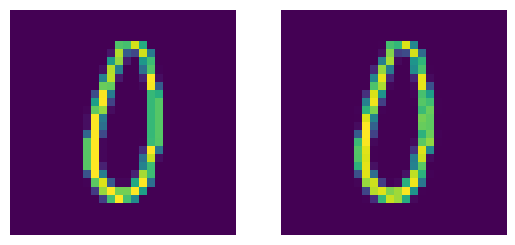

Batch n°1 - loss_val: 19.1028 ; loss_reco_val: 17.455 ; loss_KLD_val: 1.6477 - lr =  0.001
epoch 3997/4000
Ep: 3997 - Batch: 1 loss: 9.525 ; loss_reco: 7.8309 ; loss_KLD: 1.6941 - beta = 1.0 - time = 06min 36sec
epoch 3998/4000
Ep: 3998 - Batch: 1 loss: 9.6359 ; loss_reco: 7.8772 ; loss_KLD: 1.7588 - beta = 1.0 - time = 06min 36sec
epoch 3999/4000
Ep: 3999 - Batch: 1 loss: 9.7285 ; loss_reco: 7.9867 ; loss_KLD: 1.7418 - beta = 1.0 - time = 06min 36sec
epoch 4000/4000
Ep: 4000 - Batch: 1 loss: 9.609 ; loss_reco: 7.8348 ; loss_KLD: 1.7742 - beta = 1.0 - time = 06min 36sec


In [126]:
# cosine_scheduler = CosineAnnealingLR(optimizer, T_max = 10, eta_min = 1e-5)
# plateau_scheduler = ReduceLROnPlateau(optimizer, factor=0.5, patience=5, cooldown=2, min_lr=1e-5)

str_loss_colnames = ["loss", "loss_reco", "loss_KLD"]

cur_epoch = 1
epochs = 4000 
anneal = 500

batchsize = X_train.shape[0]//10




batch_range_train = range(0, X_train.shape[0] +1, batchsize)
batch_range_val = range(0, X_val.shape[0] +1, batchsize)
ratio = 100 /batchsize /np.prod(X_train.shape[1:]) # Avoir une erreur relative à la dimension des données et de la taille du batch

# Passe le modèle en mode "apprentissage"
network = network.to(device)
network = network.train()


print(f"{cur_epoch}/{epochs}, Entraînement du modèle")

AVG_loss = []
Val_loss = []
learning_rates = []
begin = time.time()
b = None
beta = 1.
for epoch in range(cur_epoch, epochs +1):
    print(f"epoch {epoch}/{epochs}")
    
    
    for i, batch in enumerate(batch_range_train[:-1]) :
        X = X_train[batch:batch_range_train[i +1]].astype(np.float32) /255.
        X = torch.from_numpy(X)
        X = X.to(device)
        
        # Calcul de l'erreur avec annealing
        losses = None
        
        if epoch <= anneal :
            b = 0
            losses = network(X, beta = b)
        elif (epoch > anneal) and (epoch < 2*anneal) :
            b = beta *(epoch/anneal -1)
            losses = network(X, beta = b)
        else :
            b = beta
            losses = network(X, beta = beta)

        # Rétropropagation du gradient
        optimizer.zero_grad()
        losses[0].backward()
        # Descente de gradient (une itération)
        optimizer.step()


        cur_lr = optimizer.param_groups[0]["lr"]
        loss = np.array([losses[0].item() *ratio] + list(losses[1:]))
        AVG_loss.append(loss)
        learning_rates.append([cur_lr, time.time() -begin, b])
        if i%10 == 0 :
            str_loss = [f"{s}: {np.round(l, 4)}" for s, l in zip(str_loss_colnames, loss)]
            str_loss = " ; ".join(str_loss)
            t = learning_rates[-1][1]
            print(f"Ep: {epoch} - Batch: {i +1} " + str_loss + f" - beta = {np.round(b, 4)} - time = {int(t//60):02d}min {int(t%60):02d}sec")
        
    
    # cosine_scheduler.step()
    # plateau_scheduler.step(loss[0])
    
    if (epoch) % 5 == 1 : 
        clear_output()
        # display train data
        display_epoch(network.vae, X[0:, :])
        plt.show()
        for i, batch in enumerate(batch_range_val[:-1]) :
            
            X = X_val[batch:batch_range_val[i +1]].astype(np.float32) /255.
            X = torch.from_numpy(X)
            X = X.to(device)
        
            losses = network(X, beta = b) 
            loss = np.array([losses[0].item() *ratio] + list(losses[1:]))
            Val_loss.append(loss)
            if i%10 == 0 :
                str_val_loss = [f"{s}_val: {np.round(l, 4)}" for s, l in zip(str_loss_colnames, loss)]
                str_val_loss = " ; ".join(str_val_loss)
                print(f"Batch n°{i+1} - " + str_val_loss, "- lr = ", cur_lr)
            
    if epoch % 2000 == 0 :
        results_rep = f"results\\VAE\\D_{D}-beta_{beta}-eff_{eff}-epoch_{epoch}"
        if not os.path.isdir(results_rep) :
            # os.mkdir(global_path)
            os.mkdir(results_rep)
            AVG = pd.DataFrame(np.array(AVG_loss), columns = str_loss_colnames)
            AVG_loss_path = os.path.join(results_rep, r"loss.csv")
            AVG.to_csv(AVG_loss_path, index = False)
            
            AVG = pd.DataFrame(np.array(Val_loss), columns = ["val_" + string for string in str_loss_colnames])
            AVG_loss_path = os.path.join(results_rep, r"validation_loss.csv")
            AVG.to_csv(AVG_loss_path, index = False)
            
            LR = pd.DataFrame(np.array(learning_rates), columns = ["learning_rate", "time", "beta"])
            LR_path = os.path.join(results_rep, r"learning_rate.csv")
            LR.to_csv(LR_path, index = False)
            
            model_path = os.path.join(results_rep, r"model.pt")
            torch.save(network, model_path)
end = time.time()

In [117]:
results_rep = f"results\\VAE\\D_{D}-beta_{beta}-eff_{eff}-epoch_{epochs}"
results_rep

'results\\VAE\\D_50-beta_1.0-eff_200-epoch_2000'

In [118]:

# ROI_rep = saving_rep + f'\\{ROI}'

if not os.path.isdir(results_rep) :
    # os.mkdir(global_path)
    os.mkdir(results_rep)
    AVG = pd.DataFrame(np.array(AVG_loss), columns = str_loss_colnames)
    AVG_loss_path = os.path.join(results_rep, r"loss.csv")
    AVG.to_csv(AVG_loss_path, index = False)
    
    AVG = pd.DataFrame(np.array(Val_loss), columns = ["val_" + string for string in str_loss_colnames])
    AVG_loss_path = os.path.join(results_rep, r"validation_loss.csv")
    AVG.to_csv(AVG_loss_path, index = False)
    
    LR = pd.DataFrame(np.array(learning_rates), columns = ["learning_rate", "time", "beta"])
    LR_path = os.path.join(results_rep, r"learning_rate.csv")
    LR.to_csv(LR_path, index = False)
    
    model_path = os.path.join(results_rep, r"model.pt")
    torch.save(network, model_path)

In [ ]:
results_rep = f"results\\VAE\\D_{D}-beta_{beta}-eff_{200}-epoch_{400}"
AVG_loss = pd.read_csv(results_rep + "\\loss.csv")
Val_loss = pd.read_csv(results_rep + "\\validation_loss.csv")
learning_rates = pd.read_csv(results_rep + "\\learning_rate.csv")

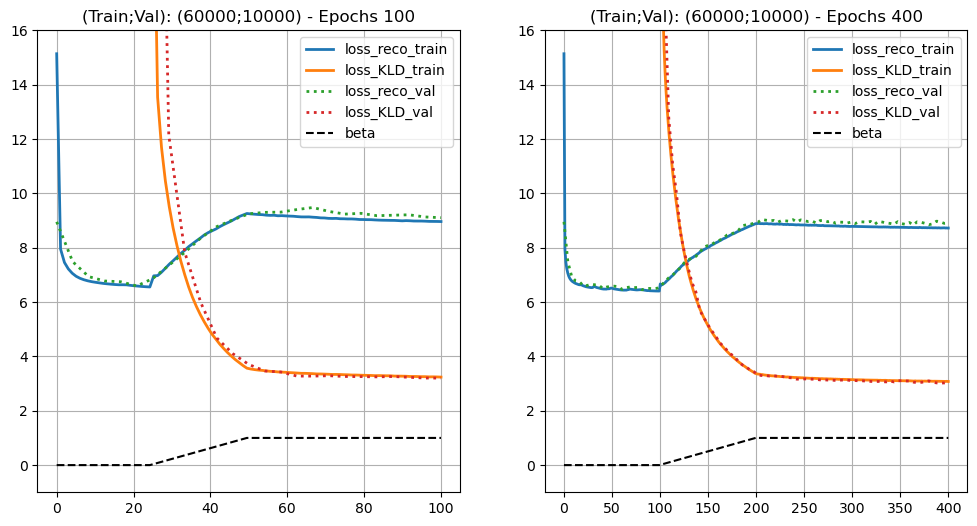

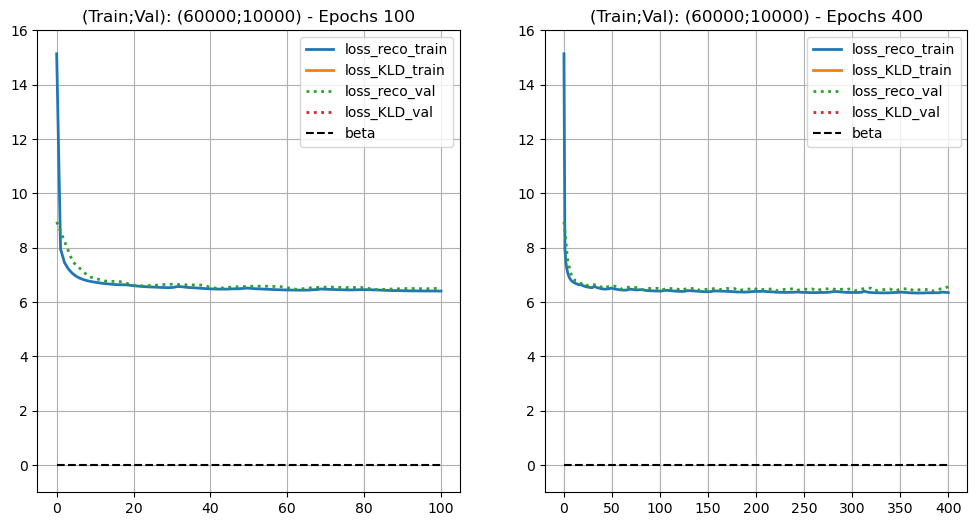

In [ ]:
for r, rep in enumerate(reps) :
    
    AVG_loss = pd.read_csv(results_rep + "\\loss.csv")
    Val_loss = pd.read_csv(results_rep + "\\validation_loss.csv")
    learning_rates = pd.read_csv(results_rep + "\\learning_rate.csv")

    length = np.prod(np.array(AVG_loss).shape)
    length_2 = np.prod(np.array(Val_loss).shape)
    n = ns[r]
    n_val = ns[r]//4
    idx = 0

    plt.subplot(1, 2, r+1)
    a_range_train = np.linspace(idx, n, n)
    a_range_val = np.linspace(idx, n, n_val)
    a_train = np.array(AVG_loss).reshape(n, length//(n*3), 3).mean(axis = 1)[:, 1:]
    a_val = np.array(Val_loss).reshape(n_val, length_2//(n_val*3), 3).mean(axis = 1)[:, 1:]
    
    plt.plot(a_range_train, a_train[idx:], linewidth = 2)
    plt.plot(a_range_val, a_val[idx:], linewidth = 2, linestyle = "dotted")

    a2 = np.array(learning_rates)[:, -1:].reshape(n, length//(n*3), 1).mean(axis = 1)
    plt.plot(a_range_train, a2[idx:], color = "k", linestyle = "dashed")
    plt.title(f"(Train;Val): ({ef};{10000}) - Epochs {ep}")
    plt.grid()
    
    plt.ylim((-1, 16))
    plt.legend([s+"_train" for s in str_loss_colnames[1:]] + [s+"_val" for s in str_loss_colnames[1:]] + ["beta"])
plt.show()

## 5. Vérification

In [312]:
from libraries.latent import get_Asquare, get_KLD

def get_MU_LOGVAR(net, X_train, batchrange) :
    MU = []
    LOGVAR = []
    for b, batch in enumerate(batchrange[:-1]) :
        X = X_train[batch:batchrange[b +1]].astype(np.float32) /255.
        X = torch.from_numpy(X)
        X = X.to(device)
        _, mu, logvar, _ = net.vae.pred(X)
        
        MU.append(mu.detach().numpy())
        LOGVAR.append(logvar.detach().numpy())

    MU = np.concatenate(MU)
    LOGVAR = np.concatenate(LOGVAR)
    return MU, LOGVAR

In [327]:
reps

['D_50-beta_1.0-eff_60000-epoch_100', 'D_50-beta_1.0-eff_60000-epoch_400']

In [395]:
reps = os.listdir(f"results\\VAE")[-2:]
seq = {}
ns = [100, 400]
for r, rep in enumerate(reps) :
    ef, ep = [int(e.split("_")[-1]) for e in rep.split("-")[-2:]]
    seq[ep] = {}
    seq[ep]["net"] = torch.load(f"results\\VAE" + "\\" + rep + r"\model.pt", weights_only=False)
    seq[ep]["net"].train(False)

    
    MU_VAL = []
    LOGVAR_VAL = []
    
    batchsize = 2000
    batch_range_train = range(0, X_TRAIN.shape[0] +1, batchsize)
    batch_range_val = range(0, X_VAL.shape[0] +1, batchsize)
    MU, LOGVAR = get_MU_LOGVAR(seq[ep]["net"], X_TRAIN, batch_range_train)
    MU_val, LOGVAR_val = get_MU_LOGVAR(seq[ep]["net"], X_VAL, batch_range_val)

    
    VAR = np.exp(LOGVAR)
    Asquare = get_Asquare(MU, VAR)
    VAR_val = np.exp(LOGVAR_val)
    Asquare_val = get_Asquare(MU_val, VAR_val)
    
    seq[ep]["MU"] = MU
    seq[ep]["VAR"] = VAR
    seq[ep]["Asquare"] = Asquare
    seq[ep]["MU_val"] = MU_val
    seq[ep]["VAR_val"] = VAR_val
    seq[ep]["Asquare_val"] = Asquare_val
    

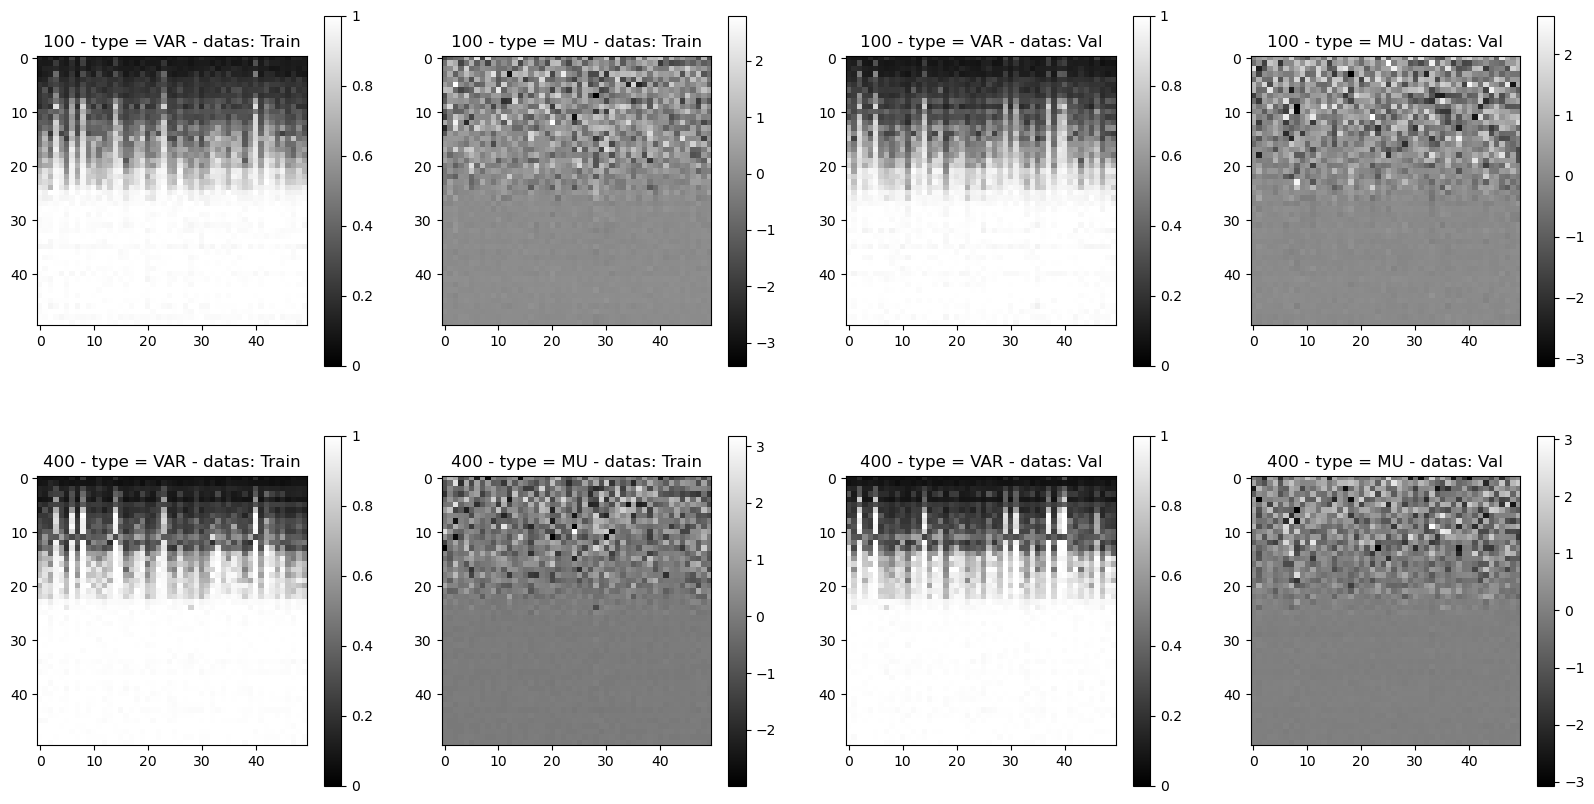

In [361]:
fig, axes = plt.subplots(len(seq.keys()), 4, figsize = (20, 10))

rang = [0, 0.2, 0.4, 0.6,0.8, 1]
for m, mode in enumerate(seq.keys()) :
    As = seq[mode]["Asquare"]
    idx = As["index"]

    As_val = seq[mode]["Asquare_val"]
    idx_val = As["index"]
    
    im = axes[m, 0].imshow(np.sqrt(seq[mode]["VAR"][:50, idx].T), cmap = "gray", vmin = 0, vmax = 1)
    axes[m, 0].set_title(f"{mode} - type = VAR - datas: Train")
    cbar = fig.colorbar(im)
    cbar.set_ticks(ticks = rang, labels = rang)
    
    im = axes[m, 1].imshow(seq[mode]["MU"][:50, idx].T, cmap = "gray")
    axes[m, 1].set_title(f"{mode} - type = MU - datas: Train")
    cbar = fig.colorbar(im)

    im = axes[m, 2].imshow(np.sqrt(seq[mode]["VAR_val"][:50, idx_val].T), cmap = "gray", vmin = 0, vmax = 1)
    axes[m, 2].set_title(f"{mode} - type = VAR - datas: Val")
    cbar = fig.colorbar(im)
    cbar.set_ticks(ticks = rang, labels = rang)
    
    im = axes[m, 3].imshow(seq[mode]["MU_val"][:50, idx_val].T, cmap = "gray")
    axes[m, 3].set_title(f"{mode} - type = MU - datas: Val")
    cbar = fig.colorbar(im)
plt.show()

In [353]:
%matplotlib inline
from ipywidgets import interact, IntSlider, Layout

axes = ["z", "y", "x"]
axis = 2

def decode_img(decoder, mu, latent_pass, lat_idx_kept, i) :
    order = np.argsort(np.abs(latent_pass))[::-1][:]
    
    sel_pat_lat = np.zeros(100).astype(np.float32)
    sel_pat_lat[lat_idx_kept] = mu[lat_idx_kept]
    sel_pat_lat[lat_idx_kept[order[:i]]] += latent_pass[order[:i]]
    hat_x = decoder(torch.from_numpy(sel_pat_lat)).detach().numpy()
    return hat_x


model_type = ["TRAIN", "VAL"]
def display_reco(idx, k, i) :
    plt.figure(figsize = (12, 6))
    x = mu = None
    if i == 0 :
        x = X_TRAIN[idx, 0].astype(np.float32) /255
        mu = seq[k]["MU"][idx]
    if i == 1 :
        x = X_VAL[idx, 0].astype(np.float32) /255
        mu = seq[k]["MU_val"][idx]
    hat_x = seq[k]["net"].vae.Decoder(torch.from_numpy(mu)).detach().numpy()[0, 0]
    diff = np.abs(x-hat_x)
    img = np.concatenate([x, hat_x, diff], axis = 1)
    
    plt.imshow(img, cmap = "gray")
    plt.title(f"Obs: {idx} - net: {k} - model type: {model_type[i]} - MAE = {np.abs(x-hat_x).mean():1.4f}")
    plt.colorbar()
    plt.axis("off")
    plt.show()

interact(display_reco,
         idx = IntSlider(min = 0, max =  200, step = 1, value= 0, description = "Observation:", layout = Layout(width = "500px")), 
         k = IntSlider(min = 100, max =  400, step = 300, value = 100, description = "Net:", layout = Layout(width = "500px")),
         i = IntSlider(min = 0, max = 1, step = 1, value= 0, description = "Data type:", layout = Layout(width = "500px"))
        )

interactive(children=(IntSlider(value=0, description='Observation:', layout=Layout(width='500px'), max=200), I…

<function __main__.display_reco(idx, k, i)>

In [406]:
%matplotlib inline
from ipywidgets import interact, IntSlider, Layout

axes = ["z", "y", "x"]
axis = 2

def decode_img(decoder, mu, vector_selected, vector_value, lat_idx_kept) :
    mu[:, lat_idx_kept[vector_selected]] = vector_value
    hat_x = decoder(torch.from_numpy(mu)).detach().numpy()[:, 0]
    return hat_x


model_type = ["TRAIN", "VAL"]
def display_reco(idx, k, i, vector_selected, vector_value) :
    plt.figure(figsize = (12, 2))
    x = mu = None
    lat_idx_kept = None
    if i == 0 :
        x = X_TRAIN[idx, 0].astype(np.float32) /255
        mu = seq[k]["MU"][idx:10+idx]
        lat_idx_kept = seq[k]["Asquare"]["index"]
    if i == 1 :
        x = X_VAL[idx, 0].astype(np.float32) /255
        mu = seq[k]["MU_val"][idx:10+idx]
        lat_idx_kept = seq[k]["Asquare_val"]["index"]

    vector_value = float(vector_value)/100 -5
    hat_x = decode_img(seq[k]["net"].vae.Decoder, mu.copy(), vector_selected, vector_value, lat_idx_kept)
    img = np.concatenate(hat_x, axis = 1)
    
    plt.imshow(img, cmap = "gray")
    plt.title(f"Vector value: {vector_value:1.3f} - net: {k} - model type: {model_type[i]}")
    plt.colorbar()
    plt.axis("off")
    plt.show()

interact(display_reco,
         idx = IntSlider(min = 0, max =  200, step = 1, value= 0, description = "Observation:", layout = Layout(width = "500px")), 
         k = IntSlider(min = 100, max =  400, step = 300, value = 100, description = "Net:", layout = Layout(width = "500px")),
         i = IntSlider(min = 0, max = 1, step = 1, value= 0, description = "Data type:", layout = Layout(width = "500px")),
         vector_selected = IntSlider(min = 0, max = 50 -1, step = 1, value= 0, description = "vector selected:", layout = Layout(width = "500px")),
         vector_value = IntSlider(min = 0, max = 1000, step = 1, value= 300, description = "vector value:", layout = Layout(width = "500px"))
        )

interactive(children=(IntSlider(value=0, description='Observation:', layout=Layout(width='500px'), max=200), I…

<function __main__.display_reco(idx, k, i, vector_selected, vector_value)>

In [408]:
%matplotlib inline
from ipywidgets import interact, IntSlider, Layout

axes = ["z", "y", "x"]
axis = 2


model_type = ["TRAIN", "VAL"]
def display_reco(idx, k, i, vector_selected, vector_value, classe) :
    plt.figure(figsize = (12, 2))
    x = mu = None
    lat_idx_kept = None
    if i == 0 :
        obs_class_idx = np.where(Y_TRAIN == classe)
        mu = seq[k]["MU"][obs_class_idx][idx:10+idx]
        lat_idx_kept = seq[k]["Asquare"]["index"]
    if i == 1 :
        obs_class_idx = np.where(Y_TRAIN == classe)
        mu = seq[k]["MU_val"][obs_class_idx][idx:10+idx]
        lat_idx_kept = seq[k]["Asquare_val"]["index"]

    vector_value = float(vector_value)/100 -5
    hat_x = decode_img(seq[k]["net"].vae.Decoder, mu.copy(), vector_selected, vector_value, lat_idx_kept)
    img = np.concatenate(hat_x, axis = 1)
    
    plt.imshow(img, cmap = "gray")
    plt.title(f"Vector value: {vector_value:1.3f} - net: {k} - model type: {model_type[i]}")
    plt.colorbar()
    plt.axis("off")
    plt.show()

interact(display_reco,
         idx = IntSlider(min = 0, max =  200, step = 1, value= 0, description = "Observation:", layout = Layout(width = "500px")), 
         k = IntSlider(min = 100, max =  400, step = 300, value = 100, description = "Net:", layout = Layout(width = "500px")),
         i = IntSlider(min = 0, max = 1, step = 1, value= 0, description = "Data type:", layout = Layout(width = "500px")),
         vector_selected = IntSlider(min = 0, max = 50 -1, step = 1, value= 0, description = "vector selected:", layout = Layout(width = "500px")),
         vector_value = IntSlider(min = 0, max = 1000, step = 1, value= 300, description = "vector value:", layout = Layout(width = "500px")),
         classe = IntSlider(min = 0, max = 9, step = 1, value= 0, description = "classe:", layout = Layout(width = "500px"))
        )

interactive(children=(IntSlider(value=0, description='Observation:', layout=Layout(width='500px'), max=200), I…

<function __main__.display_reco(idx, k, i, vector_selected, vector_value, classe)>